<a href="https://colab.research.google.com/github/nn250327/DLcat2l26/blob/main/dlcat2l26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kaggle

In [ ]:
from google.colab import files
import os

print("Please upload your 'kaggle.json' file.")
uploaded = files.upload()

if "kaggle.json" in uploaded:
    os.makedirs("/root/.kaggle", exist_ok=True)

    with open("/root/.kaggle/kaggle.json", "wb") as f:
        f.write(uploaded["kaggle.json"])

    os.chmod("/root/.kaggle/kaggle.json", 0o600)
    print("Kaggle API configured successfully.")
else:
    print("Error: 'kaggle.json' was not uploaded. You uploaded:", list(uploaded.keys()))
    print("Please run this cell again and select your Kaggle API token file ('kaggle.json').")

Please upload your 'kaggle.json' file.


Saving emergency_dispatch_traffic_synthetic_10000.csv to emergency_dispatch_traffic_synthetic_10000 (1).csv
Error: 'kaggle.json' was not uploaded. You uploaded: ['emergency_dispatch_traffic_synthetic_10000 (1).csv']
Please run this cell again and select your Kaggle API token file ('kaggle.json').


In [ ]:
!kaggle datasets download \
    -d razanihababdellatif/emergency-dispatch-and-traffic-physics-dataset \
    -p /content

Traceback (most recent call last):
  File "/usr/local/bin/kaggle", line 4, in <module>
    from kaggle.cli import main
  File "/usr/local/lib/python3.13/dist-packages/kaggle/__init__.py", line 10, in <module>
    api.authenticate()
    ~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/kaggle/api/kaggle_api_extended.py", line 763, in authenticate
    if self._authenticate_with_legacy_apikey():
       ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/kaggle/api/kaggle_api_extended.py", line 808, in _authenticate_with_legacy_apikey
    raise ValueError("Error: Missing %s in configuration." % item)
ValueError: Error: Missing username in configuration.


In [ ]:
import zipfile
import glob
import os

zip_files = glob.glob("/content/*.zip")

if not zip_files:
    print("ZIP file not found. Check the download step.")
else:
    with zipfile.ZipFile(zip_files[0], "r") as z:
        z.extractall("/content/emergency_dataset")

    print("Extracted files:")
    for root, dirs, filenames in os.walk(
        "/content/emergency_dataset"
    ):
        for name in filenames:
            print(os.path.join(root, name))

ZIP file not found. Check the download step.


In [ ]:
import pandas as pd
import glob

csv_files = glob.glob(
    "/content/emergency_dataset/**/*.csv",
    recursive=True
)

if not csv_files:
    print("No CSV file found. Check the extracted files.")
else:
    df = pd.read_csv(csv_files[0])

    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())

    df_10000 = df.sample(
        n=min(10000, len(df)),
        random_state=42
    )

    df_10000.to_csv(
        "/content/emergency_traffic_10000.csv",
        index=False
    )

    from google.colab import files
    files.download("/content/emergency_traffic_10000.csv")

No CSV file found. Check the extracted files.


In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Saving emergency_dispatch_traffic_synthetic_10000.csv to emergency_dispatch_traffic_synthetic_10000 (2).csv
Dataset loaded successfully!
Number of records: 10000
Number of columns: 13


,timestamp,road_id,hour,day_of_week,is_weekend,weather,incident_reported,vehicle_count,average_speed_kmh,congestion_index,estimated_delay_minutes,dispatch_priority,dispatch_distance_km
0,2025-01-01 00:00:00,R01,0,2,0,Clear,0,273,59.2,0.502,12.9,Routine,2.7
1,2025-01-01 00:15:00,R05,0,2,0,Cloudy,0,356,53.5,0.893,18.5,Urgent,10.7
2,2025-01-01 00:30:00,R04,0,2,0,Cloudy,0,418,54.0,0.518,19.4,Urgent,9.2
3,2025-01-01 00:45:00,R03,0,2,0,Clear,0,393,58.1,0.852,18.8,Routine,7.8
4,2025-01-01 01:00:00,R03,1,2,0,Clear,0,352,40.9,0.740,16.3,Urgent,10.7


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['timestamp', 'road_id', 'hour', 'day_of_week', 'is_weekend', 'weather', 'incident_reported', 'vehicle_count', 'average_speed_kmh', 'congestion_index', 'estimated_delay_minutes', 'dispatch_priority', 'dispatch_distance_km']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                10000 non-null  object 
 1   road_id                  10000 non-null  object 
 2   hour                     10000 non-null  int64  
 3   day_of_week              10000 non-null  int64  
 4   is_weekend               10000 non-null  int64  
 5   weather                  10000 non-null  object 
 6   incident_reported        10000 non-null  int64  
 7   vehicle_count            10000 non-null  int64  
 8   average_speed_kmh        10000 non-null  float64
 9   congestion_index         10000 no

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,10000,10000,2025-04-14 23:45:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
road_id,10000,6,R02,1718,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hour,10000.0,NaN,NaN,NaN,11.484,6.928676,0.0,5.0,11.0,17.0,23.0
day_of_week,10000.0,NaN,NaN,NaN,3.016,2.000036,0.0,1.0,3.0,5.0,6.0
is_weekend,10000.0,NaN,NaN,NaN,0.288,0.452854,0.0,0.0,0.0,1.0,1.0
weather,10000,3,Clear,5958,NaN,NaN,NaN,NaN,NaN,NaN,NaN
incident_reported,10000.0,NaN,NaN,NaN,0.0615,0.240257,0.0,0.0,0.0,0.0,1.0
vehicle_count,10000.0,NaN,NaN,NaN,437.7577,154.632008,20.0,324.0,411.0,544.0,920.0
average_speed_kmh,10000.0,NaN,NaN,NaN,42.06742,11.264231,5.0,33.3,44.4,50.6,72.0
congestion_index,10000.0,NaN,NaN,NaN,0.781126,0.193983,0.182,0.625,0.806,0.993,1.0


In [ ]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Create time-based features
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek

# Sort observations by time
df = df.sort_values("timestamp").reset_index(drop=True)

# Target variable
target = "congestion_index"

# Select input features
features = [
    "hour",
    "day_of_week",
    "is_weekend",
    "weather",
    "incident_reported",
    "vehicle_count",
    "average_speed_kmh",
    "road_id",
    "dispatch_priority",
    "dispatch_distance_km"
]

X = df[features]
y = df[target]

print("Input features:", features)
print("Target variable:", target)
print("Total observations:", len(df))

Input features: ['hour', 'day_of_week', 'is_weekend', 'weather', 'incident_reported', 'vehicle_count', 'average_speed_kmh', 'road_id', 'dispatch_priority', 'dispatch_distance_km']
Target variable: congestion_index
Total observations: 10000


In [ ]:
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8000
Testing records: 2000


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

numeric_features = [
    "hour",
    "day_of_week",
    "is_weekend",
    "incident_reported",
    "vehicle_count",
    "average_speed_kmh",
    "dispatch_distance_km"
]

categorical_features = [
    "weather",
    "road_id",
    "dispatch_priority"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual_Congestion": y_test.values,
    "Predicted_Congestion": y_pred
})

display(results.head(10))

,Actual_Congestion,Predicted_Congestion
0,0.733,0.64583
1,1.000,1.00000
2,1.000,0.99420
3,1.000,0.99007
4,1.000,0.98437
5,1.000,0.99972
6,1.000,0.99934
7,0.972,0.91465
8,0.782,0.71656
9,0.473,0.51382


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("----------------")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MODEL EVALUATION
----------------
MAE  : 0.0494
RMSE : 0.0674
R²   : 0.8804


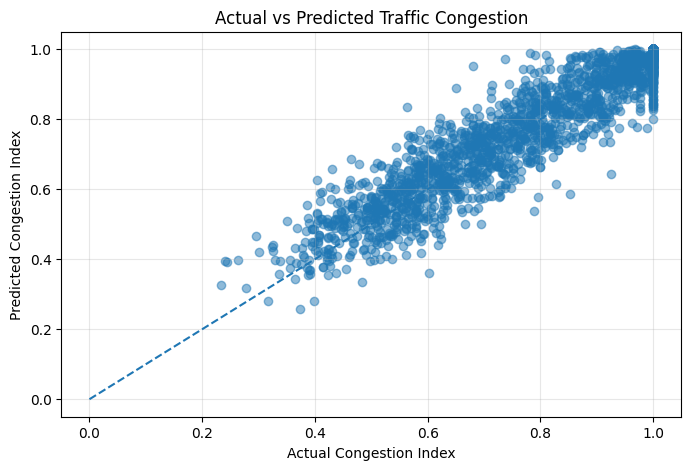

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("Actual Congestion Index")
plt.ylabel("Predicted Congestion Index")
plt.title("Actual vs Predicted Traffic Congestion")
plt.grid(True, alpha=0.3)
plt.show()

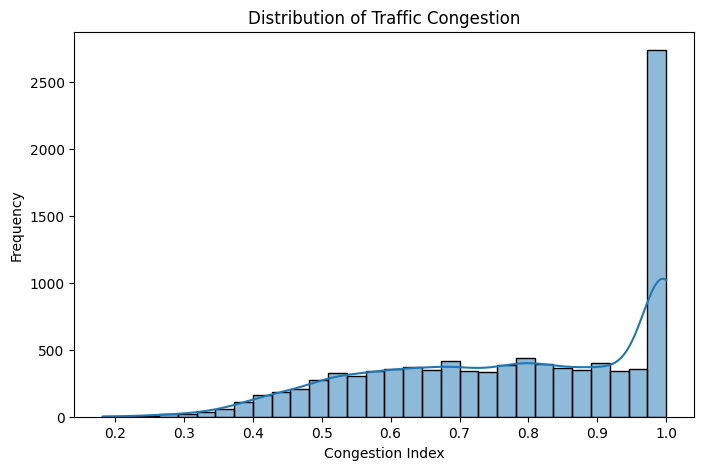

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["congestion_index"],
    bins=30,
    kde=True
)

plt.title("Distribution of Traffic Congestion")
plt.xlabel("Congestion Index")
plt.ylabel("Frequency")
plt.show()

In [ ]:
new_traffic = pd.DataFrame([{
    "hour": 18,
    "day_of_week": 2,
    "is_weekend": 0,
    "weather": "Rain",
    "incident_reported": 1,
    "vehicle_count": 650,
    "average_speed_kmh": 25,
    "road_id": "R03",
    "dispatch_priority": "Critical",
    "dispatch_distance_km": 8.0
}])

predicted_congestion = model.predict(new_traffic)[0]

print("Predicted congestion index:",
      round(predicted_congestion, 3))

Predicted congestion index: 1.0


In [ ]:
from google.colab import files

results["Absolute_Error"] = (
    results["Actual_Congestion"]
    - results["Predicted_Congestion"]
).abs()

results.to_csv(
    "traffic_prediction_results.csv",
    index=False
)

df.to_csv(
    "emergency_traffic_processed.csv",
    index=False
)

files.download("traffic_prediction_results.csv")
files.download("emergency_traffic_processed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>